In [1]:
using Pkg
Pkg.activate("psyc261")
Pkg.add("Conda")
using Conda
Conda.add("numpy")
Pkg.add(["Distributions", "ProgressMeter", "Gen", "Plots", "Parameters", "PyCall", "Colors", "JSON"])
ENV["PYTHON"] = "/Library/Frameworks/Python.framework/Versions/3.10/bin/python3.10"
Pkg.build("PyCall")

  Activating project at `~/Desktop/25FA/PSYC 5610/project/basic copy/psyc261`
    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
  No Changes to `~/Desktop/25FA/PSYC 5610/project/basic copy/psyc261/Project.toml`
  No Changes to `~/Desktop/25FA/PSYC 5610/project/basic copy/psyc261/Manifest.toml`
┌ Info: Running `conda install -y numpy` in root environment
└ @ Conda /Users/jinnie/.julia/packages/Conda/05AVg/src/Conda.jl:181


Retrieving notices: done
Channels:
 - defaults
 - conda-forge
Platform: osx-arm64
Solving environment: done




==> WARNING: A newer version of conda exists. <==
    current version: 25.9.1
    latest version: 25.11.0

Please update conda by running

    $ conda update -n base -c conda-forge conda





# All requested packages already installed.



   Resolving package versions...
  No Changes to `~/Desktop/25FA/PSYC 5610/project/basic copy/psyc261/Project.toml`
  No Changes to `~/Desktop/25FA/PSYC 5610/project/basic copy/psyc261/Manifest.toml`
    Building Conda ─→ `~/.julia/scratchspaces/44cfe95a-1eb2-52ea-b672-e2afdf69b78f/8f06b0cfa4c514c7b9546756dbae91fcfbc92dc9/build.log`
    Building PyCall → `~/.julia/scratchspaces/44cfe95a-1eb2-52ea-b672-e2afdf69b78f/9816a3826b0ebf49ab4926e2b18842ad8b5c8f04/build.log`


In [2]:
using Pkg
using Distributions
using ProgressMeter
using Gen, Plots
using Parameters
using PyCall
using Colors
np = pyimport("numpy")
;

In [3]:
# import mitsuba using pycall
mi = pyimport("mitsuba")

# different rendering modes of mitsuba 
mi.variants()
mi.set_variant("scalar_rgb")

---

In [4]:
# Alt2. python dict
@pyinclude("./scene_patch.py")

scene_d = py"initialize_scene()"o::PyObject

# load the scene using the load_dict function
scene::PyObject = @pycall mi.load_dict(scene_d)::PyObject

image = @pycall mi.render(scene, spp=128)::PyObject
bitmap = @pycall mi.Bitmap(image).convert(srgb_gamma=true)::PyObject

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

In [5]:
# 1. Helper: Convert u'v' (CIE 1976) -> xy (CIE 1931)
function uv_to_xy(u_prime, v_prime)
    # Inverse formula from CIE 1976 to 1931
    denominator = 6 * u_prime - 16 * v_prime + 12
    if denominator == 0
        return (0.0, 0.0)
    end
    x = 9 * u_prime / denominator
    y = 4 * v_prime / denominator
    return (x, y)
end

# 2. Main Converter: u'v' + Brightness -> RGB
function uv_to_mitsuba_rgb(u_prime, v_prime, Y_value)
    # Step A: Get xy chromaticity
    x, y = uv_to_xy(u_prime, v_prime)
    
    # Step B: Convert to XYZ Tristimulus
    if y == 0
        X, Z = 0.0, 0.0
    else
        X = (Y_value / y) * x
        Z = (Y_value / y) * (1 - x - y)
    end
    
    # Create the XYZ color object
    xyz_color = XYZ(X, Y_value, Z)
    
    # Step C: Convert to RGB
    return convert(RGB, xyz_color)
end

uv_to_mitsuba_rgb (generic function with 1 method)

In [6]:
# color change trial
# (scene_d, bsdf_id, new_rgb_value)
bsdf_id = "glossy-sphere"
# new_rgb_value = [0.1, 0.8, 0.1]
new_uv_value = [0.23, 0.38]
Y_value = 0.3
rgb_color = uv_to_mitsuba_rgb(new_uv_value[1], new_uv_value[2], Y_value)
new_rgb_value = [rgb_color.r, rgb_color.g, rgb_color.b]
new_alpha = 0.01
# 1. Get the BSDF dictionary (e.g., 'glossy-sphere')
bsdf_dict = PyObject(get(scene_d, bsdf_id))
light_dict = PyObject(get(scene_d, "light"))
emitter_dict = PyObject(get(light_dict, "emitter"))
# new_lightuv_value = [0.1978, 0.4683]
new_lightuv_value = [0.2, 0.38]
light_rgb_color = uv_to_mitsuba_rgb(new_lightuv_value[1], new_lightuv_value[2], 1)
new_light_value = [light_rgb_color.r, light_rgb_color.g, light_rgb_color.b]*50
println(new_light_value)

# 2. Get the 'diffuse_reflectance' sub-dictionary
# This sub-dictionary holds the color definition for the non-specular component.
reflectance_dict = PyObject(get(bsdf_dict, "diffuse_reflectance"))

# 3. Set the new RGB list value
set!(reflectance_dict, "value", new_rgb_value)
set!(bsdf_dict, "alpha", new_alpha)
set!(bsdf_dict, "diffuse_reflectance", reflectance_dict)

set!(emitter_dict, "radiance", Dict("type" => "rgb", "value" => new_light_value))
set!(light_dict, "emitter", emitter_dict)
set!(scene_d, "light", light_dict)
set!(scene_d, bsdf_id, bsdf_dict)

scene = @pycall mi.load_dict(scene_d)::PyObject
image = @pycall mi.render(scene, spp=128)::PyObject
# get the bitmap, which Jupyter notebook displays inline!
bitmap = @pycall mi.Bitmap(image).convert(srgb_gamma=true)::PyObject

[50.0, 46.110644163473914, 50.0]


PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

---
## inverse graphics

In [7]:
rgb = uv_to_mitsuba_rgb(0.14, 0.38, 0.3)
println(rgb)
swatch = fill(rgb, 1, 1)

RGB{Float64}(0.0, 0.6297693056861497, 0.8978213993718868)


In [9]:
# the with_kw macro comes from the Parameters package 
# and is a handy macro for having default values to certain entries in a Julia struct.
@with_kw struct ModelParams
    scene_d::PyDict
    scene::PyObject = @pycall mi.load_dict(scene_d)::PyObject
    spp::Int32 = 128
end;

function color_change!(scene_d, bsdf_id, new_uv_value, new_alpha, new_lightuv_value)
    Y_value = 0.3
    rgb_color = uv_to_mitsuba_rgb(new_uv_value[1], new_uv_value[2], Y_value)
    new_rgb_value = [rgb_color.r, rgb_color.g, rgb_color.b]

    light_rgb_color = uv_to_mitsuba_rgb(new_lightuv_value[1], new_lightuv_value[2], 1)
    new_light_value = [light_rgb_color.r, light_rgb_color.g, light_rgb_color.b]*50
    
    # 1. Get the BSDF dictionary (e.g., 'glossy-sphere')
    bsdf_dict = PyObject(get(scene_d, bsdf_id))
    light_dict = PyObject(get(scene_d, "light"))
    emitter_dict = PyObject(get(light_dict, "emitter"))
    reflectance_dict = PyObject(get(bsdf_dict, "diffuse_reflectance"))

    # 3. Set the new RGB list value
    set!(emitter_dict, "radiance", Dict("type" => "rgb", "value" => new_light_value))
    set!(light_dict, "emitter", emitter_dict)
    set!(scene_d, "light", light_dict)
    set!(reflectance_dict, "value", new_rgb_value)
    set!(bsdf_dict, "alpha", new_alpha)

    set!(bsdf_dict, "diffuse_reflectance", reflectance_dict)
    set!(scene_d, bsdf_id, bsdf_dict)
    return scene_d
end

function light_change!()
    
end

function render_bitmap(modelparams)
    image = @pycall mi.render(modelparams.scene, spp=modelparams.spp)::PyObject
    bitmap = @pycall mi.Bitmap(image).convert(srgb_gamma=true)::PyObject
    return bitmap
end

function render(modelparams)
    bitmap = render_bitmap(modelparams)
    mu = @pycall np.array(bitmap)::Array{Float32, 3}
    return mu
end

render (generic function with 1 method)

In [10]:
@gen function room()
    scene_d = py"initialize_scene()"o::PyObject
    
    u ~ uniform(0.11,0.27)
    v ~ uniform(0.39,0.55)
    a ~ uniform(0.01, 0.99)
    
    light_u ~ uniform(0.11,0.27)
    light_v ~ uniform(0.39,0.55)
    light_intensity = 50

    # color change
    bsdf_id = "glossy-sphere"
    # new_rgb_value = [r, g, b]
    # new_light_value = [light_r, light_g, light_b]*light_intensity
    new_uv_value = [u, v]
    new_lightuv_value = [light_u, light_v]
    new_alpha = a
    # println("New light value: ", new_lightuv_value)
    color_change!(scene_d, bsdf_id, new_uv_value, new_alpha, new_lightuv_value)

    # load the resulting scene into our struct
    # Notice that we are using a much cheaper spp for inference
    modelparams = ModelParams(scene_d=scene_d, spp=128)

    # render into an array
    mu = render(modelparams)

    # define the likelihood as a gaussian with diagonal covariance
    pred ~ broadcasted_normal(mu, 1.0)

end

function view_image(t)
    scene_d = py"initialize_scene()"o::PyObject
    # t_left = [-0.3, -0.5, 0.2]
    # transform!(scene_d, "left-object", t[:s_left], t_left)
    # t_right = [0.5, -0.75, -0.2] 
    # transform!(scene_d, "right-object", t[:s_right], t_right)
    #scene = mi.load_dict(scene_d)
    # color_change!(scene_d, "glossy-sphere", [t[:r], t[:g], t[:b]], t[:a], [t[:light_r], t[:light_g], t[:light_b]])
    color_change!(scene_d, "glossy-sphere", [t[:u], t[:v]], t[:a], [t[:light_u], t[:light_v]])
    scene_to_render = ModelParams(scene_d=scene_d)
    bitmap = render_bitmap(scene_to_render)
end
;

In [11]:
# draw a random sample from the generative model
trace = Gen.simulate(room, ())
get_choices(trace)

│
├── :a : 0.5588731198067804
│
├── :light_v : 0.46096739197958275
│
├── :pred : [-0.6319500662522773 1.306824668434119 -1.6154540330402647 0.5607515099685525 -0.31719530211975117 -0.22573731584339607 0.0435423245374927 0.225273540128633 2.82777742041292 -0.1332793312115218 0.5457490371519269 -1.8225627523069767 -0.8945431273066451 -0.33047607672854906 -0.8038022794029502 0.6905017013803314 0.7912566000257021 0.6583130118954574 -0.9691577317079534 1.147982841671518 -0.4761195323177572 -1.6384297551662406 0.5824397510416699 -0.5681641416436163 -1.2177288422972976 1.6173124321380794 0.289732004659296 -1.673334171426255 -0.37528778623314696 1.138644721499988 -0.4069040408940407 0.48837888967834775 -0.4740979436993144 -0.5694787836863581 -0.4032243196317799 0.5327360839234808 0.8878945999870695 0.9257810871868268 -1.884853915273409 -0.9321410457049709 0.07639989974440857 -1.475407757622723 -0.3282555524484855 -1.3778650819686227 0.9945612768100722 -0.7548011768677918 -0.0392232177442135 -0

In [12]:
view_image(trace)

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

---

In [20]:
# alt1. load the scene from an xml file (instead of a dict)
# obs_scene_config = mi.load_file("./scenes/cbox.xml")
# obs_scene = ModelParams(scene_d=PyDict(), scene=obs_scene_config, spp=128)
# obs_bitmap = render_bitmap(obs_scene)

# alt2. load from python dict (original)
obs_scene_config = py"initialize_scene()"o::PyObject
# obj = [0.19, 0.47]
obj = [0.26, 0.4]
light = [0.19, 0.47]
# light = [0.12,0.4]
alpha_value = 0.01
color_change!(obs_scene_config, "glossy-sphere", obj, alpha_value, light)
obs_scene = @pycall mi.load_dict(obs_scene_config)::PyObject
obs_image = @pycall mi.render(obs_scene, spp=128)::PyObject
obs_bitmap = @pycall mi.Bitmap(obs_image).convert(srgb_gamma=true)::PyObject

obs_image = Gen.choicemap()
p = @pycall np.array(obs_bitmap)::Array{Float64, 3}
obs_image[:pred] = p
# again, hoping to avoid that nasty bug...
obs_scene = 1
# to view the image on your notebook
obs_bitmap

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

In [14]:
include("truncatednorm.jl")
# proposal distribution for the scale variables
@gen function scale_proposal(current_trace)
    # trunc_norm(mean, std, lower_bound, upper_bound)
    u ~ trunc_norm(current_trace[:u], 0.04, 0.11, 0.27)
    v ~ trunc_norm(current_trace[:v], 0.04, 0.39, 0.55)
    a ~ trunc_norm(current_trace[:a], 0.25, 0.01, 0.99)
    light_u ~ trunc_norm(current_trace[:light_u], 0.04, 0.11, 0.27)
    light_v ~ trunc_norm(current_trace[:light_v], 0.04, 0.39, 0.55)
end

function random_walk_mh(tr)
    # make a random-walk update on scale variables
    (tr, accepted) = mh(tr, scale_proposal, ())

    # return the updated trace
    tr
end
;

In [15]:
function do_inference(image, K = 100)
    t, = generate(room, (), image)
    scores = Vector{Float64}(undef, K)
    best_score = -Inf
    best_t = t
    @showprogress for i in 1:K
        t = random_walk_mh(t)
        scores[i] = get_score(t)
        if scores[i] > best_score
            best_score = scores[i]
            best_t = t
        end
    end;
    return scores, best_t
end
;

In [21]:
(scores, best_t) = do_inference(obs_image,100)
get_choices(best_t)
view_image(best_t)

Progress: 100%|█████████████████████████████████████████| Time: 0:01:21


PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

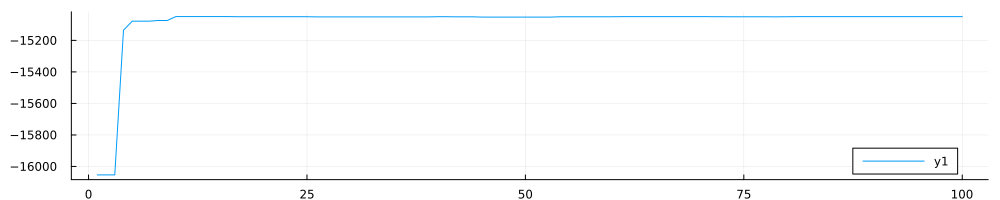

In [72]:
plot(scores, size = (1000, 200))

In [57]:
view_image(best_t)

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

In [33]:
obs_bitmap

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

In [34]:
get_choices(best_t)

│
├── :a : 0.07756431916207207
│
├── :light_v : 0.43055607829174697
│
├── :pred : [0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

---
*try a higher alpha one*

In [ ]:
# change alpha to 0.99

bsdf_id = "glossy-sphere"

new_alpha = 0.99
# 1. Get the BSDF dictionary (e.g., 'glossy-sphere')
new_obs_scene_config = py"initialize_scene()"o::PyObject
color_change!(new_obs_scene_config, "glossy-sphere", [0.23, 0.38], new_alpha, [0.19, 0.47])
new_obs_scene = @pycall mi.load_dict(new_obs_scene_config)::PyObject
new_obs_image = @pycall mi.render(new_obs_scene, spp=128)::PyObject
new_obs_bitmap = @pycall mi.Bitmap(new_obs_image).convert(srgb_gamma=true)::PyObject

new_obs_image = Gen.choicemap()
p = @pycall np.array(new_obs_bitmap)::Array{Float64, 3}
new_obs_image[:pred] = p
# again, hoping to avoid that nasty bug...
new_obs_scene = 1
# to view the image on your notebook
new_obs_bitmap

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

In [36]:
# call the inference procedure
(scores, best_t) = do_inference(new_obs_image, 50)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:46


([-15062.233898865125, -15062.233898865125, -15062.233898865125, -15062.233898865125, -15062.233898865125, -15062.233898865125, -15058.756736503214, -15058.756736503214, -15058.756736503214, -15058.756736503214  …  -15056.902797325876, -15056.902797325876, -15056.902797325876, -15056.902797325876, -15056.902797325876, -15056.902797325876, -15056.902797325876, -15056.902797325876, -15056.902797325876, -15056.902797325876], Gen.DynamicDSLTrace{DynamicDSLFunction{Any}}(DynamicDSLFunction{Any}(Dict{Symbol, Any}(), Dict{Symbol, Any}(), Type[], false, Union{Nothing, Some{Any}}[], Main.var"##room#235", Bool[], false), Trie{Any, Gen.ChoiceOrCallRecord}(Dict{Any, Gen.ChoiceOrCallRecord}(:a => Gen.ChoiceOrCallRecord{Float64}(0.1964799037458997, 1.6607312068216509, NaN, true), :light_v => Gen.ChoiceOrCallRecord{Float64}(0.4168659737361704, 1.6094379124341003, NaN, true), :pred => Gen.ChoiceOrCallRecord{Matrix{Float64}}([0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.

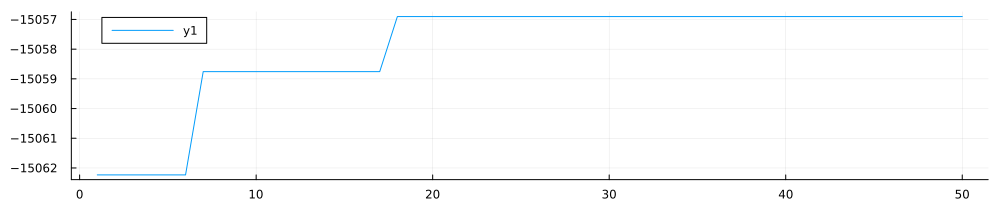

In [37]:
plot(scores, size = (1000, 200))

In [38]:
view_image(best_t)

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

In [39]:
new_obs_bitmap

PyObject Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [128, 128],
  srgb_gamma = 1,
  struct = Struct<12>[
    float32 R; // @0, gamma, premultiplied alpha
    float32 G; // @4, gamma, premultiplied alpha
    float32 B; // @8, gamma, premultiplied alpha
  ],
  data = [ 192 KiB of image data ]
]

In [55]:
get_choices(best_t)
# best_t[:a]

│
├── :a : 0.1964799037458997
│
├── :light_v : 0.4168659737361704
│
├── :pred : [0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.

---

In [ ]:
using DelimitedFiles
using Dates

function run_and_save(obj_uv::Vector{Float64}, light_uv::Vector{Float64}, alpha::Float64; runs::Int=5, K::Int=100, redo::Bool=false)
    # Prepare observed scene and image (same pattern used above)
    obs_scene_config = py"initialize_scene()"o::PyObject
    color_change!(obs_scene_config, "glossy-sphere", obj_uv, alpha, light_uv)
    obs_scene = @pycall mi.load_dict(obs_scene_config)::PyObject
    obs_image_py = @pycall mi.render(obs_scene, spp=128)::PyObject
    obs_bitmap = @pycall mi.Bitmap(obs_image_py).convert(srgb_gamma=true)::PyObject
    p = @pycall np.array(obs_bitmap)::Array{Float64, 3}

    # create an observed choicemap and attach the predicted image
    obs_image = Gen.choicemap()
    obs_image[:pred] = p
    # Avoid the bug used earlier (match previous notebook pattern)
    obs_scene = 1

    # Build results directory name using the provided parameters
    dir_name = "results_objUV_$(round(obj_uv[1]; digits=3))_$(round(obj_uv[2]; digits=3))__lightUV_$(round(light_uv[1]; digits=3))_$(round(light_uv[2]; digits=3))__alpha_$(alpha)"
    all_csv = joinpath(dir_name, "all_runs.csv")

    # If directory exists and redo is false, skip doing the runs
    if isdir(dir_name) && !redo
        println("Directory exists: $dir_name. Skipping runs. To overwrite, set redo=true.")
        if isfile(all_csv)
            return all_csv
        else
            # Directory exists but CSV missing — return path and warn
            println("Warning: directory exists but $all_csv is missing.")
            return all_csv
        end
    end

    # Create directory (mkpath is safe if it already exists)
    mkpath(dir_name)

    # Save the observed bitmap as PNG (preview) — keep PNG, remove .npy/.json/.txt saves
    try
        pil = pyimport("PIL.Image")
        a = p
        a_min = minimum(a)
        a_max = maximum(a)
        if a_max > a_min
            norm = ((a .- a_min) ./ (a_max - a_min)) .* 255.0
        else
            norm = a .* 255.0
        end
        norm_uint8 = convert(Array{UInt8,3}, round.(norm))
        img = pil.fromarray(norm_uint8)
        img.save(joinpath(dir_name, "obs_bitmap.png"))
    catch e
        println("Could not save obs PNG (PIL may be missing): ", e)
    end

    # Prepare combined CSV for all runs (kept)
    header = "obj_u,obj_v,light_u,light_v,alpha,scores\n"
    open(all_csv, "w") do io
        write(io, header)
    end

    for i in 1:runs
        println("Run $i / $runs: starting inference (K=$K)...")
        (scores, best_t) = do_inference(obs_image, K)

        # Convert scores vector to a single string (semicolon-separated)
        scores_str = join(string.(scores), ";")

        # Append a row to the combined CSV
        line = "$(best_t[:u]),$(best_t[:v]),$(best_t[:light_u]),$(best_t[:light_v]),$(best_t[:a]),\"$scores_str\"\n"
        open(all_csv, "a") do io
            write(io, line)
        end

        # Save a PNG of the scores plot for convenience
        try
            plt = plot(scores, size = (1000, 200))
            savefig(joinpath(dir_name, "scores_run$(i).png"))
        catch e
            println("Warning: failed to save scores plot: ", e)
        end

        # Render and save the inferred image for best_t as PNG (no .npy)
        try
            bmp = view_image(best_t)
            arr = @pycall np.array(bmp)::Array{Float64,3}
            pil = pyimport("PIL.Image")
            a = arr
            a_min = minimum(a)
            a_max = maximum(a)
            if a_max > a_min
                norm = ((a .- a_min) ./ (a_max - a_min)) .* 255.0
            else
                norm = a .* 255.0
            end
            norm_uint8 = convert(Array{UInt8,3}, round.(norm))
            img = pil.fromarray(norm_uint8)
            img.save(joinpath(dir_name, "inferred_image_run$(i).png"))
        catch e
            println("Could not save inferred PNG (PIL may be missing): ", e)
        end

        println("Run $i complete — appended row to: $all_csv and saved inferred PNG/scores plot")
    end
    println("All runs complete. Combined results CSV: $all_csv")
    return all_csv
end


run_and_save (generic function with 1 method)

In [17]:
Y = [0.23,0.51]
W = [0.19,0.47]
B = [0.15,0.43]
G = [0.15,0.51]
R = [0.23,0.43]
colors = [W,Y,B,R,G]

5-element Vector{Vector{Float64}}:
 [0.19, 0.47]
 [0.23, 0.51]
 [0.15, 0.43]
 [0.23, 0.43]
 [0.15, 0.51]

In [73]:
# for color in colors
    # run_and_save(W, color, 0.01; runs=3, K=100)
    # run_and_save(W, color, 0.99; runs=3, K=100)
# end
run_and_save(W, W, 0.01; runs=3, K=100)
# run_and_save(W, R, 0.99; runs=3, K=100)

Directory exists: results_objUV_0.19_0.47__lightUV_0.19_0.47__alpha_0.01. Skipping runs. To overwrite, set redo=true.


"results_objUV_0.19_0.47__lightUV_0.19_0.47__alpha_0.01/all_runs.csv"